# Receipt model comparison and visualizations

Compare the new **CORD SmolVLM**, the earlier **SROIE SmolVLM**, and **Gemini 3.5 Flash-Lite** on the same held-out CORD receipts. The earlier adapter receives the same item-extraction prompt as the new one: its item result is a task-transfer baseline, because it was trained for company/date/address/total. This notebook does not claim that its original item-extraction accuracy existed.

The new model's recorded training run has completed. The embedded curve below uses its actual saved losses. Three-model extraction results remain **pending** until inference is run. Token loss is not accuracy, and no missing result is shown as a measured zero.

Run from the project directory with `experiments/benchmarks/receipt_benchmark.py`, `experiments/smolvlm/inference.py`, both adapter folders, and their exported metadata. CPU is sufficient to read results and draw charts. Local inference requires CUDA; the runner loads the two adapters sequentially using 4-bit bases. The API requires internet and `GEMINI_API_KEY` in `.env`.

Start with **10 test receipts**. A completed fresh run sends one Gemini request per selected receipt. No confidence requests or API warm-up calls are added. Cached successful results are reused; changed weights, prompt, resolution or token limits select a new cache. Selecting 100 receipts means up to 100 fresh Gemini requests; check your project quota first.

In [1]:
# Install once from the repository root in a terminal:
# python -m pip install -r requirements/experiments.txt
# Use a CUDA-enabled PyTorch build for local model inference.


In [ ]:
from pathlib import Path
import sys

# Works from the repository root or a notebook subdirectory. Training notebooks
# also remain standalone on an A100 when only the notebook has been uploaded.
PROJECT_ROOT = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / "pyproject.toml").is_file()
     and (candidate / "packages/receipt_extraction").is_dir()),
    Path.cwd(),
)
for path in (PROJECT_ROOT, PROJECT_ROOT / "packages"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
print("Project directory:", PROJECT_ROOT)


In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from experiments.benchmarks.receipt_benchmark import (
    MODEL_LABELS, training_audit, prepare_examples, run_benchmark,
    load_results, summarize_records, plot_training, plot_comparison, read_json, write_json,
)

CORD_ADAPTER = (PROJECT_ROOT / "model/smolvlm-cord-items-lora")
OLD_ADAPTER = (PROJECT_ROOT / "model/smolvlm-receipt-lora")
RESULTS = (PROJECT_ROOT / "results/model_comparison")
MODELS = ["cord_smolvlm", "sroie_smolvlm", "gemini"]
N_RECEIPTS = 10       # 0 selects the entire manifest test split (100 in this export)
SEED = 42
IMAGE_EDGE = 768      # shared longest-edge setting; Gemini receives a JPEG at this size
MAX_NEW_TOKENS = 2048 # shared output ceiling; Gemini may use part of this for thinking
GEMINI_MODEL = "gemini-3.5-flash-lite"
GEMINI_DELAY = 13     # seconds between new API requests; actual quotas are project-specific

# Set these True to execute work. All default to False so opening/running the visualization
# notebook does not download data or submit API requests automatically.
PREPARE_IMAGES = False
RUN_LOCAL_MODELS = False
RUN_GEMINI = False
RETRY_OPERATIONAL_ERRORS = False
RESULTS.mkdir(parents=True, exist_ok=True)

## Inspect the completed training run

These measurements come from `training_summary.json`, `training_log.json`, and `dataset_manifest.json` in the downloaded CORD adapter. Validation is teacher-forced answer-token loss. A low loss alone cannot establish correct item grouping, complete lists, or accurate totals on new receipts.

In [3]:
audit = training_audit(CORD_ADAPTER)
write_json(RESULTS / "training_audit.json", audit)
display(pd.DataFrame(audit["validation_by_epoch"]))
print("Optimizer updates:", audit["optimizer_steps"])
print("Smoke test:", audit["smoke_test"])
print("Effective splits:", audit["effective_split_counts"])
print(f"Validation-loss reduction from epoch 1: {audit['validation_loss_reduction_percent']:.2f}%")
print("Saved test metrics:", audit["saved_test_metrics"])

,epoch,step,validation_loss
0,1,100,0.202385
1,2,200,0.181438
2,3,300,0.172955


Optimizer updates: 300
Smoke test: False
Effective splits: {'train': 796, 'validation': 100, 'test': 100}
Validation-loss reduction from epoch 1: 14.54%
Saved test metrics: None


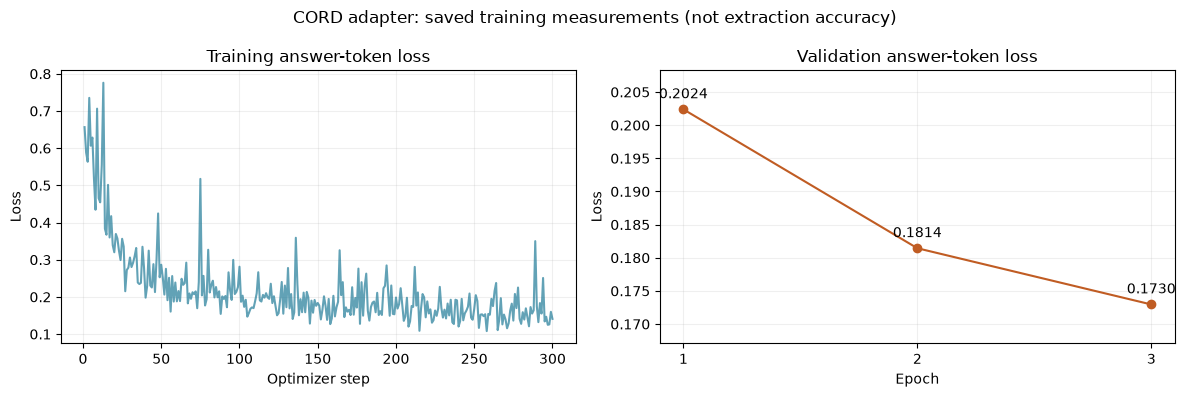

In [4]:
fig = plot_training(CORD_ADAPTER, RESULTS)
plt.show()

## Prepare a reproducible held-out sample

Preparation uses the exact source revisions, row indices, RGB image hashes and converted reference targets saved during training. It uses only manifest records assigned to `test` and rejects overlap with train/validation. Images are cached as PNGs after their hashes are verified. You do not need SROIE test data for this benchmark.

Set `PREPARE_IMAGES = True` for the first run, or use the command below in a terminal. Internet or the relevant Hugging Face cache is required. Returned examples and provenance are written to `results/model_comparison/examples.json`.

```bash
python -m experiments.benchmarks.receipt_benchmark --prepare --limit 10
```

A 10-receipt result is an initial diagnostic, not a reliable final ranking. Use the full held-out set after checking runtime and API quotas. Each model gets the same receipt image, target task, longest-edge setting and output-token ceiling. Native processors and tokenizers differ, and equal ceilings do not imply equal compute or text capacity.

In [5]:
if PREPARE_IMAGES:
    example_config = prepare_examples(CORD_ADAPTER, RESULTS, limit=N_RECEIPTS, seed=SEED)
    print("Prepared test receipts:", len(example_config["examples"]))
elif (RESULTS / "examples.json").exists():
    example_config = read_json(RESULTS / "examples.json")
    print("Using existing selected receipts:", len(example_config["examples"]))
else:
    example_config = None
    print("No test images prepared yet. Enable PREPARE_IMAGES or run the preparation command.")

No test images prepared yet. Enable PREPARE_IMAGES or run the preparation command.


## Run inference and cache responses

Enable `RUN_LOCAL_MODELS` on the machine whose GPU performance you want to measure. The new model's matching base revision is loaded from its export. Both adapters use the CORD prompt for this comparison; the old adapter file is unchanged. Confidence scoring is disabled for all models.

Enable `RUN_GEMINI` to send the selected receipts to Google with a nested item schema and minimal thinking. It requires a project with available quota. Operational API failures stop further Gemini requests; fix the cause before enabling `RETRY_OPERATIONAL_ERRORS`. No automatic switch to a different model or paid service occurs.

Each result is cached after completion. Token usage includes all cached API attempts that reported usage, including successful requests outside the eventual paired subset. Latency excludes model loading but includes API network time; the first local call may include initialization overhead. Peak GPU memory is the PyTorch allocated peak for local inference, not the service-side memory used by Gemini.

In [6]:
selected_to_run = []
if RUN_LOCAL_MODELS:
    selected_to_run += [name for name in MODELS if name != "gemini"]
if RUN_GEMINI and "gemini" in MODELS:
    selected_to_run.append("gemini")
if selected_to_run:
    if example_config is None:
        raise RuntimeError("Prepare the test images first.")
    run_benchmark(
        RESULTS, models=selected_to_run, cord_adapter=CORD_ADAPTER, old_adapter=OLD_ADAPTER,
        image_edge=IMAGE_EDGE, max_tokens=MAX_NEW_TOKENS, gemini_model=GEMINI_MODEL,
        gemini_delay=GEMINI_DELAY, retry_errors=RETRY_OPERATIONAL_ERRORS,
    )
else:
    print("Inference is disabled; only cached results will be visualized.")

Inference is disabled; only cached results will be visualized.


## Compare accuracy on the same receipts

The main comparison uses the **intersection of receipts with returned model outputs for all selected models**. Invalid output counts as an extraction error. Network/quota/OOM failures are operational errors and are reported separately, rather than quietly changing one model's test sample. Completion counts remain visible. If there are no shared results, metrics stay unavailable.

- **Printed total accuracy:** exact annotated string after trimming outer whitespace. We do not guess locale-specific currency conversions.
- **Main item micro F1:** match multisets of `(description, quantity, unit_price, line_total)` after case/whitespace normalization. Duplicate purchases count separately; item ordering does not affect this score.
- **Description F1:** main item descriptions only, useful for separating text-reading errors from numeric/association errors.
- **Schema validity:** exact target structure, required keys and value types, including nested items.
- **Full receipt exact match:** entire predicted structure versus reference, including order and subitems.

The total chart includes 95% Wilson intervals. These reflect sample-size uncertainty, not data representativeness or model training contamination. CORD may be familiar to a hosted foundation model; these results measure performance on this benchmark, not proof of unseen-receipt generalization. Treat output scores from the earlier scripts separately; they are not comparable calibrated confidence measures.

In [7]:
summary, prediction_records = None, {}
if example_config is not None:
    example_config, prediction_records = load_results(
        RESULTS, MODELS, CORD_ADAPTER, OLD_ADAPTER, IMAGE_EDGE, MAX_NEW_TOKENS, GEMINI_MODEL,
    )
    summary = summarize_records(prediction_records, example_config["examples"], MODELS)
    write_json(RESULTS / "comparison_metrics.json", summary)
    metrics = pd.DataFrame(summary["summary"])
    display(metrics[["label", "selected_receipts", "attempted_receipts", "pending_receipts", "operational_errors",
                     "paired_receipts", "total_accuracy", "item_f1", "description_f1", "schema_valid_rate", "full_receipt_exact_match"]])
    metrics.to_csv(RESULTS / "comparison_metrics.csv", index=False)
    if not summary["paired_example_ids"]:
        print("No shared completed outputs yet. Accuracy comparisons are pending, not zero.")
else:
    print("Three-model test comparison pending. Training curves above are actual measured losses.")

Three-model test comparison pending. Training curves above are actual measured losses.


In [8]:
if summary is not None and summary["paired_example_ids"]:
    fig = plot_comparison(summary, RESULTS)
    plt.show()
else:
    print("Accuracy plots will appear after all selected models return outputs for a common receipt set.")

Accuracy plots will appear after all selected models return outputs for a common receipt set.


In [9]:
if summary is not None and summary["paired_example_ids"]:
    table = pd.DataFrame(summary["summary"]).set_index("label")
    display(table[["execution_devices", "median_latency_seconds", "max_peak_gpu_gib", "api_input_tokens", "api_output_tokens", "api_thinking_tokens", "api_total_tokens"]])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for axis, metric, title in zip(axes, ["median_latency_seconds", "max_peak_gpu_gib"],
                                   ["Median end-to-end inference latency (s)", "Peak local allocated GPU memory (GiB)"]):
        values = table[metric].dropna()
        if not values.empty:
            values.plot.bar(ax=axis, color="#207b98", rot=25)
        axis.set_title(title)
        axis.set_xlabel("")
        axis.grid(axis="y", alpha=0.2)
    fig.tight_layout()
    fig.savefig(RESULTS / "comparison_efficiency.png", dpi=180, bbox_inches="tight")
    plt.show()
    print("Gemini GPU memory is unavailable. API latency includes networking; compare hardware/service conditions when interpreting speed.")

## Inspect individual predictions

Choose a receipt index to display its source image, reference JSON and each model's output/error. A missing prediction remains missing. This helps reveal omitted rows, quantity formatting, subtotal/total confusion and submenu errors that a single aggregate metric can hide.

In [10]:
EXAMPLE_INDEX = 0
if example_config is not None:
    from PIL import Image
    example = example_config["examples"][EXAMPLE_INDEX]
    path = Path(example["image_path"])
    if not path.is_file():
        path = RESULTS / "test_images" / f"{example['id']}.png"
    if path.is_file():
        with Image.open(path) as image:
            preview = image.convert("RGB")
        preview.thumbnail((600, 900))
        display(preview)
    print("REFERENCE:", json.dumps(example["reference"], ensure_ascii=False, indent=2))
    for model_name in MODELS:
        row = next((row for row in prediction_records.get(model_name, []) if row["example_id"] == example["id"]), None)
        print("\n" + MODEL_LABELS[model_name] + ":")
        print(json.dumps(row if row is not None else {"status": "pending"}, ensure_ascii=False, indent=2))

## Reading the results

The embedded training figure shows optimization progress, not a three-model accuracy ranking. Once the benchmark finishes, use paired total accuracy and item F1 together with invalid-output and operational-error counts. Check examples before changing the model or claiming a performance advantage.

The CORD adapter is trained for this item task, while the earlier SROIE adapter is a transfer baseline. Testing only on CORD also does not establish whether the new adapter preserves SROIE performance. A separate SROIE total-extraction evaluation and verified receipts from the future application's users would answer those questions.

Outputs include `training_audit.json`, PNG charts, `comparison_metrics.json`/CSV, cached model responses and image provenance under `results/model_comparison/`. Keep this folder to resume or share results; it is ignored by Git. The API key is never written into those results. Do not tune on the held-out examples and then report the same set as an untouched test.